In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings('ignore')


In [2]:
file_path  = r"A:\Downloads\data science projects\customer-churn-project\data\raw\telco_churn.csv"

df = pd.read_csv(file_path)

print("Data Loaded successfully !")
print(f"shape:{df.shape}")

Data Loaded successfully !
shape:(50000, 34)


In [3]:
# to labeling the churn column 
df["churn"] = df['churn'].map({"Yes" : 1 , "No" : 0})

# check thev value count 
print(df["churn"].value_counts())

churn
0    36500
1    13500
Name: count, dtype: int64


In [6]:
# we drop the unnecessary  column
df = df.drop('customer_id' , axis = 1)

print("cunstomer id dropped ")
print(f"New shape :{ df.shape}")

cunstomer id dropped 
New shape :(50000, 33)


In [8]:
#we convert all categorical columns into int 
# we use label encoder 
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

categorical_col = df.select_dtypes(include=["str" , "object"]).columns

# tranform the columns 

for col in categorical_col:
    df[col] = le.fit_transform(df[col])

print("LabelEncoding are completed ")
print(f"remaining text columns : {len(df.select_dtypes(include=['str' , 'object']).columns)}")

LabelEncoding are completed 
remaining text columns : 0


In [9]:
display(df.head())

df.info()

,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,international_plan,...,total_day_calls,total_eve_calls,total_night_calls,total_intl_calls,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,churn
0,1,26,0,0,2,19,0,0,0,1,...,14,5,21,6,1,1168.44,22132.63,3,1,0
1,0,53,0,11,0,61,1,1,2,1,...,82,49,54,10,5,726.35,44364.05,2,0,0
2,0,23,0,10,2,28,1,0,2,0,...,17,83,88,4,1,430.73,12100.16,3,1,0
3,0,41,0,5,1,56,0,1,1,0,...,3,72,75,11,6,592.51,33121.13,3,1,0
4,1,43,0,6,2,1,2,0,3,0,...,3,0,63,8,2,803.61,767.07,3,1,0


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  50000 non-null  int64  
 1   age                     50000 non-null  int64  
 2   senior_citizen          50000 non-null  int64  
 3   state                   50000 non-null  int64  
 4   city_tier               50000 non-null  int64  
 5   tenure_months           50000 non-null  int64  
 6   contract_type           50000 non-null  int64  
 7   plan_type               50000 non-null  int64  
 8   data_plan               50000 non-null  int64  
 9   international_plan      50000 non-null  int64  
 10  voicemail_plan          50000 non-null  int64  
 11  multiple_lines          50000 non-null  int64  
 12  online_security         50000 non-null  int64  
 13  online_backup           50000 non-null  int64  
 14  device_protection       50000 non-null  int64  
 

In [10]:
# train test spilt 
x = df.drop('churn' , axis = 1)

y = df["churn"]

x_train  , x_test , y_train , y_test  = train_test_split(
x, y, test_size = 0.2 , random_state=42, stratify=y
)

print("x_train shape : ", x_train.shape)
print("x_test shape : ", x_test.shape)


x_train shape :  (40000, 32)
x_test shape :  (10000, 32)


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# x_train fit and tranform 
x_train_scaled = scaler.fit_transform(x_train)

#x_test fir and transform 
x_test_scaled = scaler.fit_transform(x_test)

print("scaling is completed ")


scaling is completed 


# Model training and Evaluation using Logistic Reg and XGBclassifeir

In [13]:

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score

# Logistic regreesion 

print("--- Training the Logistic Regreesion")

lr_model = LogisticRegression(max_iter=1000 , random_state=42)
lr_model.fit(x_train_scaled , y_train)
lr_predict = lr_model.predict(x_test_scaled)

print("Logistic Regression result: ")
print(classification_report(y_test , lr_predict))



# adcanced model training 

print("--- Training XGBclassifier ")

xgb_model = XGBClassifier(use_label_encoder = False , eval_metric = "logloss" , random_state = 42)

xgb_model.fit(x_train , y_train)
xgb_predict = xgb_model.predict(x_test)

print("XGBoost Result: ")
print(classification_report(y_test , xgb_predict))

--- Training the Logistic Regreesion
Logistic Regression result: 
              precision    recall  f1-score   support

           0       0.91      0.94      0.93      7300
           1       0.82      0.76      0.79      2700

    accuracy                           0.89     10000
   macro avg       0.87      0.85      0.86     10000
weighted avg       0.89      0.89      0.89     10000

--- Training XGBclassifier 
XGBoost Result: 
              precision    recall  f1-score   support

           0       0.93      0.94      0.93      7300
           1       0.83      0.80      0.82      2700

    accuracy                           0.90     10000
   macro avg       0.88      0.87      0.87     10000
weighted avg       0.90      0.90      0.90     10000



# RandomForest vs LIGHT GBM classifier

In [14]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report
import time

#1  Random forest 
print("-- Random Forest classifier-- ")
start_rf = time.time()

rf_model = RandomForestClassifier(n_estimators=100 , random_state=42)
rf_model.fit(x_train, y_train)
rf_predict = rf_model.predict(x_test)

end_rf = time.time()

print(f"time taken : {round(end_rf-start_rf,2)} seconds")
print("Random Forest Results: ")
print(classification_report(y_test , rf_predict))


# LightGBM model 
print("-- Training Light GBM --")
start_lgbm = time.time()

lgbm_model  = LGBMClassifier(random_state=42 ,verbose= -1 )
lgbm_model.fit(x_train , y_train)
lgbm_pred = lgbm_model.predict(x_test)

end_lgbm = time.time()
print(f'Time Taken : {round(end_lgbm - start_lgbm , 2)} seconds')
print("LightGBM results : ")
print(classification_report(y_test , lgbm_pred))

-- Random Forest classifier-- 
time taken : 6.67 seconds
Random Forest Results: 
              precision    recall  f1-score   support

           0       0.91      0.95      0.93      7300
           1       0.85      0.76      0.80      2700

    accuracy                           0.90     10000
   macro avg       0.88      0.85      0.87     10000
weighted avg       0.90      0.90      0.90     10000

-- Training Light GBM --
Time Taken : 0.26 seconds
LightGBM results : 
              precision    recall  f1-score   support

           0       0.93      0.94      0.94      7300
           1       0.84      0.82      0.83      2700

    accuracy                           0.91     10000
   macro avg       0.89      0.88      0.88     10000
weighted avg       0.91      0.91      0.91     10000



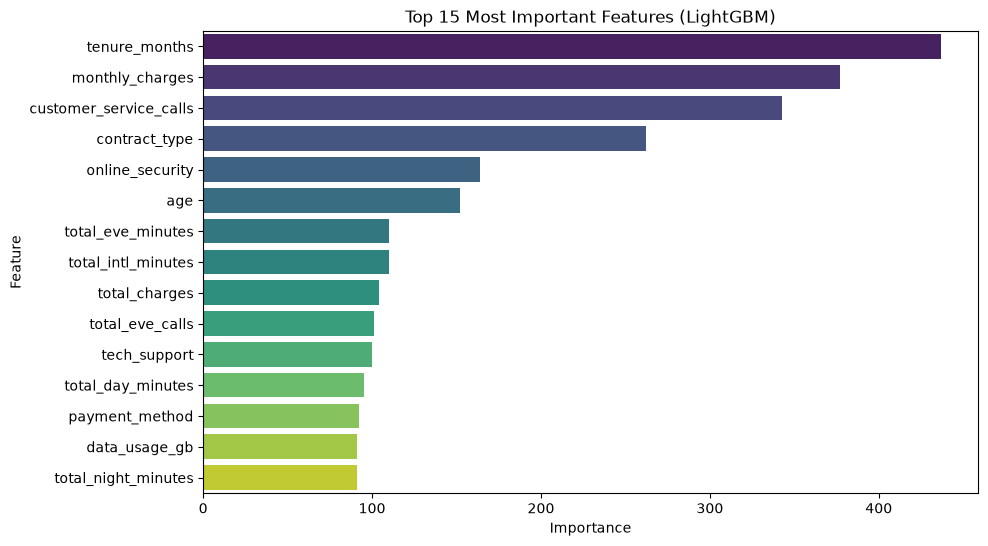

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# LightGBM se feature importance nikaalo
feature_importances = lgbm_model.feature_importances_

# Ek dataframe banao jisme feature ka naam aur uski importance ho
importance_df = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

# Top 15 features ka graph banayein
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x='Importance', y='Feature', palette='viridis')
plt.title("Top 15 Most Important Features (LightGBM)")
plt.show()

In [16]:
# Top 15 features ki list nikaalo
top_15_features = importance_df.head(15)['Feature'].tolist()

# X_train aur X_test ko sirf in top 15 features par filter karo
X_train_reduced = x_train[top_15_features]
X_test_reduced = x_test[top_15_features]

# Naya LightGBM model train karo
lgbm_reduced = LGBMClassifier(random_state=42, verbose=-1)
lgbm_reduced.fit(X_train_reduced, y_train)
preds_reduced = lgbm_reduced.predict(X_test_reduced)

from sklearn.metrics import classification_report
print("--- LightGBM Results (With Top 15 Features) ---")
print(classification_report(y_test, preds_reduced))

--- LightGBM Results (With Top 15 Features) ---
              precision    recall  f1-score   support

           0       0.93      0.94      0.94      7300
           1       0.84      0.82      0.83      2700

    accuracy                           0.91     10000
   macro avg       0.89      0.88      0.88     10000
weighted avg       0.91      0.91      0.91     10000



In [17]:
import joblib 
import os
model_dir = "A:\Downloads\data science projects\customer-churn-project\models"

# to saving the LightGBM model (33 features )
joblib.dump(lgbm_model , os.path.join(model_dir , 'lgbm_churn_model.pkl'))

# scaler save
joblib.dump(scaler , os.path.join(model_dir, 'scaler.pkl'))
print("final model and scaler are saved successfully ")

final model and scaler are saved successfully 
